In [1]:
import scanpy as sc
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import scvelo as scv
import anndata as ad
import pickle as pkl
import seaborn as sns
import scipy.sparse as sp

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA
import umap
from itertools import product

python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"
python_plot_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\plots"

## Load ATAC data and subset Peaks

In [2]:
adata_atac_full = sc.read_h5ad(fr"{python_data_dir}\all_atac_peaks_corr.h5ad")  #corr for "corrected"
peak_type_annotation = pd.read_csv(rf"{python_data_dir}\Exp4_ctr_peak_types.csv", header=0, index_col=0)
peak_type_annotation = peak_type_annotation[peak_type_annotation["peak_id"].isin(adata_atac_full.var_names.values)]
print("All indices present:", (peak_type_annotation["peak_id"].isin(adata_atac_full.var_names.values)).all())
keep_peaks = peak_type_annotation.loc[peak_type_annotation["peakType"]=="Promoter"]  # left with roughly 27k peaks for promoters
adata_atac_full = adata_atac_full[:, adata_atac_full.var_names.isin(keep_peaks["peak_id"])]

All indices present: True


## Load RNA data and subset to select HVGs

In [3]:
adata_rna = sc.read_h5ad(rf"{python_data_dir}\total_counts_raw.h5ad")

In [4]:
adata_rna.obs_names = [i[9:-2] for i in adata_rna.obs_names.values]

In [5]:
# right after reading all_rna_counts.h5ad, before the HVG subset
adata_rna.obs["depth"] = np.asarray(adata_rna.X.sum(1)).ravel()
# right after reading all_atac_peaks_corr.h5ad, before the promoter subset
adata_atac_full.obs["depth"] = np.asarray(adata_atac_full.X.sum(1)).ravel()

nn_idx_path = rf"{python_data_dir}\nn_idx.txt"
nn_dist_path = rf"{python_data_dir}\nn_dist.txt"
nn_cells_path = rf"{python_data_dir}\nn_cells.txt"

nn_idx = np.loadtxt(str(nn_idx_path), delimiter=',')
nn_dist = np.loadtxt(str(nn_dist_path), delimiter=',')
nn_cells = pd.Index(pd.read_csv(str(nn_cells_path), header=None)[0])
nn_cells = nn_cells.str.replace('-1', '', regex=False)

shared_cells = pd.Index(np.intersect1d(adata_rna.obs_names, adata_atac_full.obs_names))
#shared_genes = pd.Index(np.intersect1d(adata_rna.var_names, adata_atac_full.var_names))
adata_rna.obs.rename(columns={"cell_type": "celltype"}, inplace=True)
adata_rna = adata_rna[shared_cells,:]
adata_atac_full = adata_atac_full[shared_cells,:]

embedding_genes = pd.read_csv(rf"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_preprocessing\data\Exp4_ctr_rna_pca_genes.csv", header=[0]).T.values.tolist()[0]
adata_rna.var['highly_variable'] = adata_rna.var_names.isin(embedding_genes)

adata_rna = adata_rna[:,adata_rna.var['highly_variable']]  # Subset to the embedding genes only, use this to subset peaks

## Subset both RNA and ATAC to have common peaks/genes

In [11]:
embedding_peaks = keep_peaks[keep_peaks["nearestGene"].isin(adata_rna.var_names.values)]
adata_atac_sub = adata_atac_full[:,embedding_peaks["peak_id"]]
atac_new_X = np.zeros(shape=adata_rna.shape)
(adata_rna.obs_names.values == adata_atac_sub.obs_names.values).all()  # indices are in the same order!

df = embedding_peaks[["peak_id", "nearestGene"]].drop_duplicates()

peak_idx = pd.Index(adata_atac_sub.var_names).get_indexer(df["peak_id"])
gene_idx = pd.Index(adata_rna.var_names).get_indexer(df["nearestGene"])

keep = (peak_idx >= 0) & (gene_idx >= 0)

M = sp.csr_matrix(
    (np.ones(keep.sum(), dtype=np.float32), (peak_idx[keep], gene_idx[keep])),
    shape=(adata_atac_sub.n_vars, adata_rna.n_vars),
)

atac_new_X = adata_atac_sub.X @ M
atac_new_X = atac_new_X.toarray()

adata_atac_pmtrs = ad.AnnData(X=atac_new_X, obs=adata_atac_sub.obs)
adata_atac_pmtrs.var_names = adata_rna.var_names
adata_atac_pmtrs.obs_names = adata_rna.obs_names

In [15]:
adata_atac_pmtrs.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\atac.h5ad")
adata_rna.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\rna.h5ad")

## Work with aligned data subsets
Begin by loading data...

In [2]:
adata_atac_all_lin = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\atac.h5ad")
adata_rna_all_lin = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\rna.h5ad")

In [3]:
adata_atac_all_lin.layers["counts"] = adata_atac_all_lin.X.copy()
adata_rna_all_lin.layers["counts"] = adata_rna_all_lin.X.copy()

In [4]:
def process_pca(adata):
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata.raw = adata.copy()

    adata.var["highly_variable"] = True

    sc.pp.scale(adata, max_value=10)
    sc.tl.pca(adata, n_comps=50)
    
    return adata

adata_rna_all_lin = process_pca(adata_rna_all_lin)
adata_atac_all_lin = process_pca(adata_atac_all_lin)

Text(0.5, 1.0, 'PCA, unflipped')

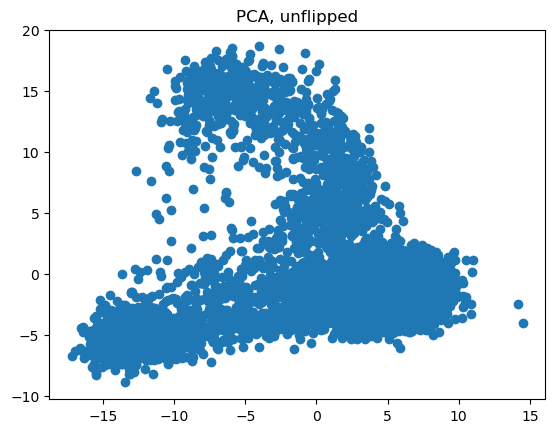

In [5]:
plt.scatter(adata_rna_all_lin.obsm["X_pca"][:,0], adata_rna_all_lin.obsm["X_pca"][:,1])
plt.title("PCA, unflipped")

In [5]:
adata_rna_proc = sc.read_h5ad(rf"{python_data_dir}\all_rna_counts.h5ad")
myeloid_cells = adata_rna_proc.obs_names[adata_rna_proc.obsm["X_pca"][:,1]<=1]
myeloid_cells_filtered = myeloid_cells[myeloid_cells.isin(adata_rna_all_lin.obs_names.values)]

This selects the correct cells, but the PCA which was built on the 700ish subsetted genes, runs in the opposite direction as I was assuming, as can be seen in the scatterplot above. The direction of pseudotime is precisely from right to left, unlike what I assumed the whole time. Because of this I will invert the x-axis of the PCA

In [6]:
adata_rna_all_lin.obsm["X_pca"][:, 0] *= -1

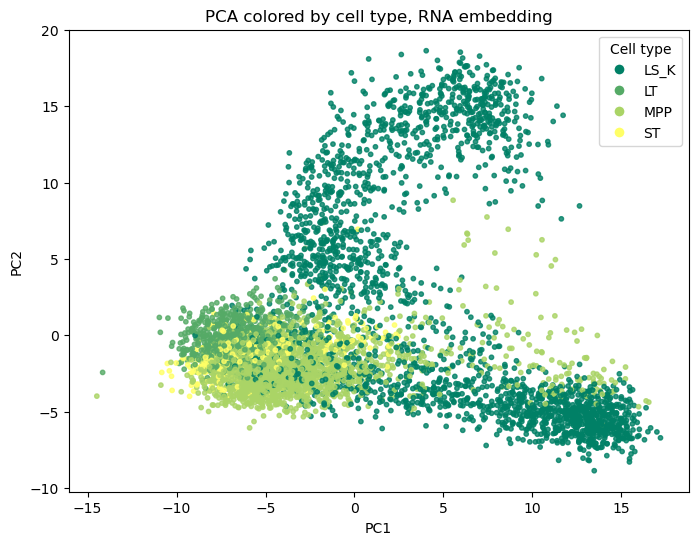

In [7]:
from matplotlib.lines import Line2D
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(["LT", "LS_K", "MPP", "ST"])
colors = le.transform(adata_rna_all_lin.obs["predicted.id"].values)
cmap = plt.get_cmap("summer", len(le.classes_))

plt.figure(figsize=(8, 6))
plt.scatter(adata_rna_all_lin.obsm["X_pca"][:,0],
     adata_rna_all_lin.obsm["X_pca"][:,1],
    c=colors,
    cmap=cmap,
    s=10,
    alpha=0.8
)

handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=cmap(i),
        markersize=8,
        label=celltype
    )
    for i, celltype in enumerate(le.classes_)
]

plt.legend(handles=handles, title="Cell type")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA colored by cell type, RNA embedding")
plt.savefig(rf"{python_plot_dir}\chromatin_potential\pca_rna_flipped.png")
plt.savefig(rf"{python_plot_dir}\chromatin_potential\pca_rna_flipped.svg")
plt.show()

In [8]:
#myeloid_cells = adata_rna_all_lin.obs_names.values[adata_rna_all_lin.obsm["X_pca"][:,1]<=1]  # filter to only myeloid lineage
adata_atac = adata_atac_all_lin[myeloid_cells_filtered,:]
adata_rna = adata_rna_all_lin[myeloid_cells_filtered,:]

# adata_rna.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_input_rna.h5ad")
# adata_atac.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_input_atac.h5ad")

# adata_rna_all_lin.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_input_rna_alllin.h5ad")
# adata_atac_all_lin.write_h5ad(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_input_atac_alllin.h5ad")

In [9]:
cell_bins_pc1 = pd.DataFrame(index=adata_rna.obs_names.values, columns=["barcode", "bin"])

min, max = np.nanquantile(adata_rna.obsm["X_pca"][:,0], 0.01), np.nanquantile(adata_rna.obsm["X_pca"][:,0], 0.99)
bin_edges = np.linspace(min, max, 11)

for i in range(len(bin_edges)-1):
    if i == 0:
        start, stop = -100, bin_edges[i+1]
    elif i == 9:
        start, stop = bin_edges[i], 100
    else: 
        start, stop = bin_edges[i], bin_edges[i+1]
    print(i, start, stop)

    bin_cells = adata_rna.obs_names.values[(adata_rna.obsm["X_pca"][:,0] > start) & (adata_rna.obsm["X_pca"][:,0] <= stop)]
    cell_bins_pc1.loc[bin_cells,"bin"] = i

cell_bins_pc1["barcode"] = cell_bins_pc1.index
cell_bins_pc1.set_index("barcode", inplace=True)

0 -100 -6.905486801147461
1 -6.905486801147461 -4.438440919876099
2 -4.438440919876099 -1.9713950386047365
3 -1.9713950386047365 0.49565084266662573
4 0.49565084266662573 2.962696723937988
5 2.962696723937988 5.42974260520935
6 5.42974260520935 7.896788486480714
7 7.896788486480714 10.363834367752075
8 10.363834367752075 12.830880249023435
9 12.830880249023435 100


In [10]:
cell_bins_pc1.to_csv(rf"{python_data_dir}\cell_bins.csv")

In [8]:
X_pca = adata_rna.obsm["X_pca"]

In [9]:
atac_df = pd.DataFrame(data=adata_atac.layers["counts"], index=adata_atac.obs_names.values, columns=adata_atac.var_names.values)
rna_df = pd.DataFrame(data=adata_rna.layers["counts"].toarray(), index=adata_rna.obs_names.values, columns=adata_rna.var_names.values)

In [10]:
def minmax_cols(df):
    mn, mx = df.min(axis=0), df.max(axis=0)
    rng = (mx - mn).replace(0, np.nan)   # constant columns would divide by zero
    return ((df - mn) / rng).fillna(0)

atac_df = minmax_cols(atac_df)
rna_df = minmax_cols(rna_df)

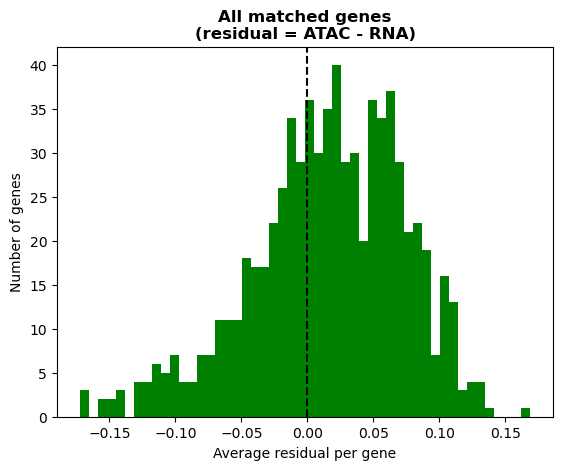

In [34]:
residual = (atac_df - rna_df).mean(axis=0)

plt.hist(residual, bins=50, color="green")
plt.axvline(0, color="black", linestyle="--")
plt.title("All matched genes\n(residual = ATAC - RNA)", fontweight="bold")
plt.xlabel("Average residual per gene")
plt.ylabel("Number of genes")
plt.savefig(rf"{python_plot_dir}\chromatin_potential\per_gene_avg_residuals.png")
plt.savefig(rf"{python_plot_dir}\chromatin_potential\per_gene_avg_residuals.svg")
plt.show()

### Calculate the smoothed curves, classify

In [11]:
def gaussian_smooth_on_grid(x, y, grid):
    sigma = 0.1 * (grid.max() - grid.min())
    x, y, grid = map(np.asarray, (x, y, grid))
    w = np.exp(-0.5 * ((grid[:, None] - x[None, :]) / sigma) ** 2)  # (n_grid, n_points)
    return ((w @ y) / w.sum(axis=1)).tolist()

def monotonic(x, eps=0.1):
    dx = np.diff(x)
    return np.all(dx >= -eps) or np.all(dx <= eps)

def monotonicity(y, min_range=0.05):
    y = np.asarray(y, float)
    rng = np.ptp(y)
    if np.isnan(y).any() or rng < min_range:
        return dict(reversal=np.nan, direction=0, ptp=rng)
    drawdown = np.max(np.maximum.accumulate(y) - y)   # largest fall after a peak (violates "increasing")
    drawup   = np.max(y - np.minimum.accumulate(y))   # largest rise after a trough (violates "decreasing")
    return dict(reversal=min(drawdown, drawup) / rng,
                direction=1 if drawdown < drawup else -1,
                ptp=rng)

def classify_shape(y, tol=0.1, min_range=0.05):
    m = monotonicity(y, min_range=min_range)
    if np.isnan(m["reversal"]):
        shape = "nan" if np.isnan(y).any() else "flat"
    elif m["reversal"] <= tol:
        shape = "up" if m["direction"] == 1 else "down"
    else:
        shape = "transient"
    return shape, m

def kernel_rate(x, C, depth, grid, sigma):
    w = np.exp(-0.5 * ((grid[:, None] - x[None, :]) / sigma) ** 2)   # (grid, cells)
    return (w @ C) / (w @ depth)[:, None]      

In [12]:
C_rna = adata_rna.X.toarray()
C_atac = np.asarray(adata_atac.layers["counts"])   # raw, set before normalize_total
depth_rna = adata_rna.obs["depth"].values
depth_atac = adata_atac.obs["depth"].values

In [13]:
gridsize = 20  # used to be 100
TOL = 0.1  # used to be 0.1
MIN_RANGE = 0.1  # used to be 0.05

monotonic_genes = {}
non_monotonic_genes = {}
skipped_zero = []

grid = np.linspace(X_pca[:, 0].min(), X_pca[:, 0].max(), gridsize)

x = X_pca[:, 0]
sigma = 0.2 * (grid.max() - grid.min())      # used to be 0.1
R_curves = kernel_rate(x, C_rna,  depth_rna,  grid, sigma)
A_curves = kernel_rate(x, C_atac, depth_atac, grid, sigma)

def minmax01(y):
    rng = y.max() - y.min()
    return (y - y.min()) / rng if rng > 0 else np.zeros_like(y)

for i, gene_name in enumerate(rna_df.columns):
    if C_atac[:, i].sum() == 0 or C_rna[:, i].sum() == 0:
        skipped_zero.append(gene_name)
        continue

    rna_m  = R_curves[:, i] / R_curves[:, i].max()     # ptp = relative amplitude (1 - min/max)
    atac_m = A_curves[:, i] / A_curves[:, i].max()

    shape_r, m_r = classify_shape(rna_m,  TOL, MIN_RANGE)   # classify on the max-scaled curves
    shape_a, m_a = classify_shape(atac_m, TOL, MIN_RANGE)

    smoothed_rna, smoothed_atac = minmax01(rna_m), minmax01(atac_m)

    entry = {"smooth_rna": smoothed_rna,
             "smooth_atac": smoothed_atac,
             "rna_shape": shape_r, "atac_shape": shape_a,
             "rna_reversal": m_r["reversal"], "atac_reversal": m_a["reversal"],
             "rna_ptp": m_r["ptp"], "atac_ptp": m_a["ptp"]}

    if shape_r in ("up", "down") and shape_a in ("up", "down"):
        monotonic_genes[gene_name] = entry
    else:
        non_monotonic_genes[gene_name] = entry

print("Monotonic:", len(monotonic_genes))
print("Non-monotonic:", len(non_monotonic_genes))
print("Skipped (all zero):", len(skipped_zero))
assert len(monotonic_genes) + len(non_monotonic_genes) + len(skipped_zero) == rna_df.shape[1]

shapes = pd.DataFrame({g: (d["rna_shape"], d["atac_shape"])
                       for g, d in {**monotonic_genes, **non_monotonic_genes}.items()},
                      index=["rna_shape", "atac_shape"]).T
print(pd.crosstab(shapes.rna_shape, shapes.atac_shape))

Monotonic: 331
Non-monotonic: 306
Skipped (all zero): 84
atac_shape  down  flat  transient   up
rna_shape                             
down         132   117         28   69
transient     24    22          8   27
up            22    72          8  108


Visualize the differnt combinations for RNA and ATAC curve shape:

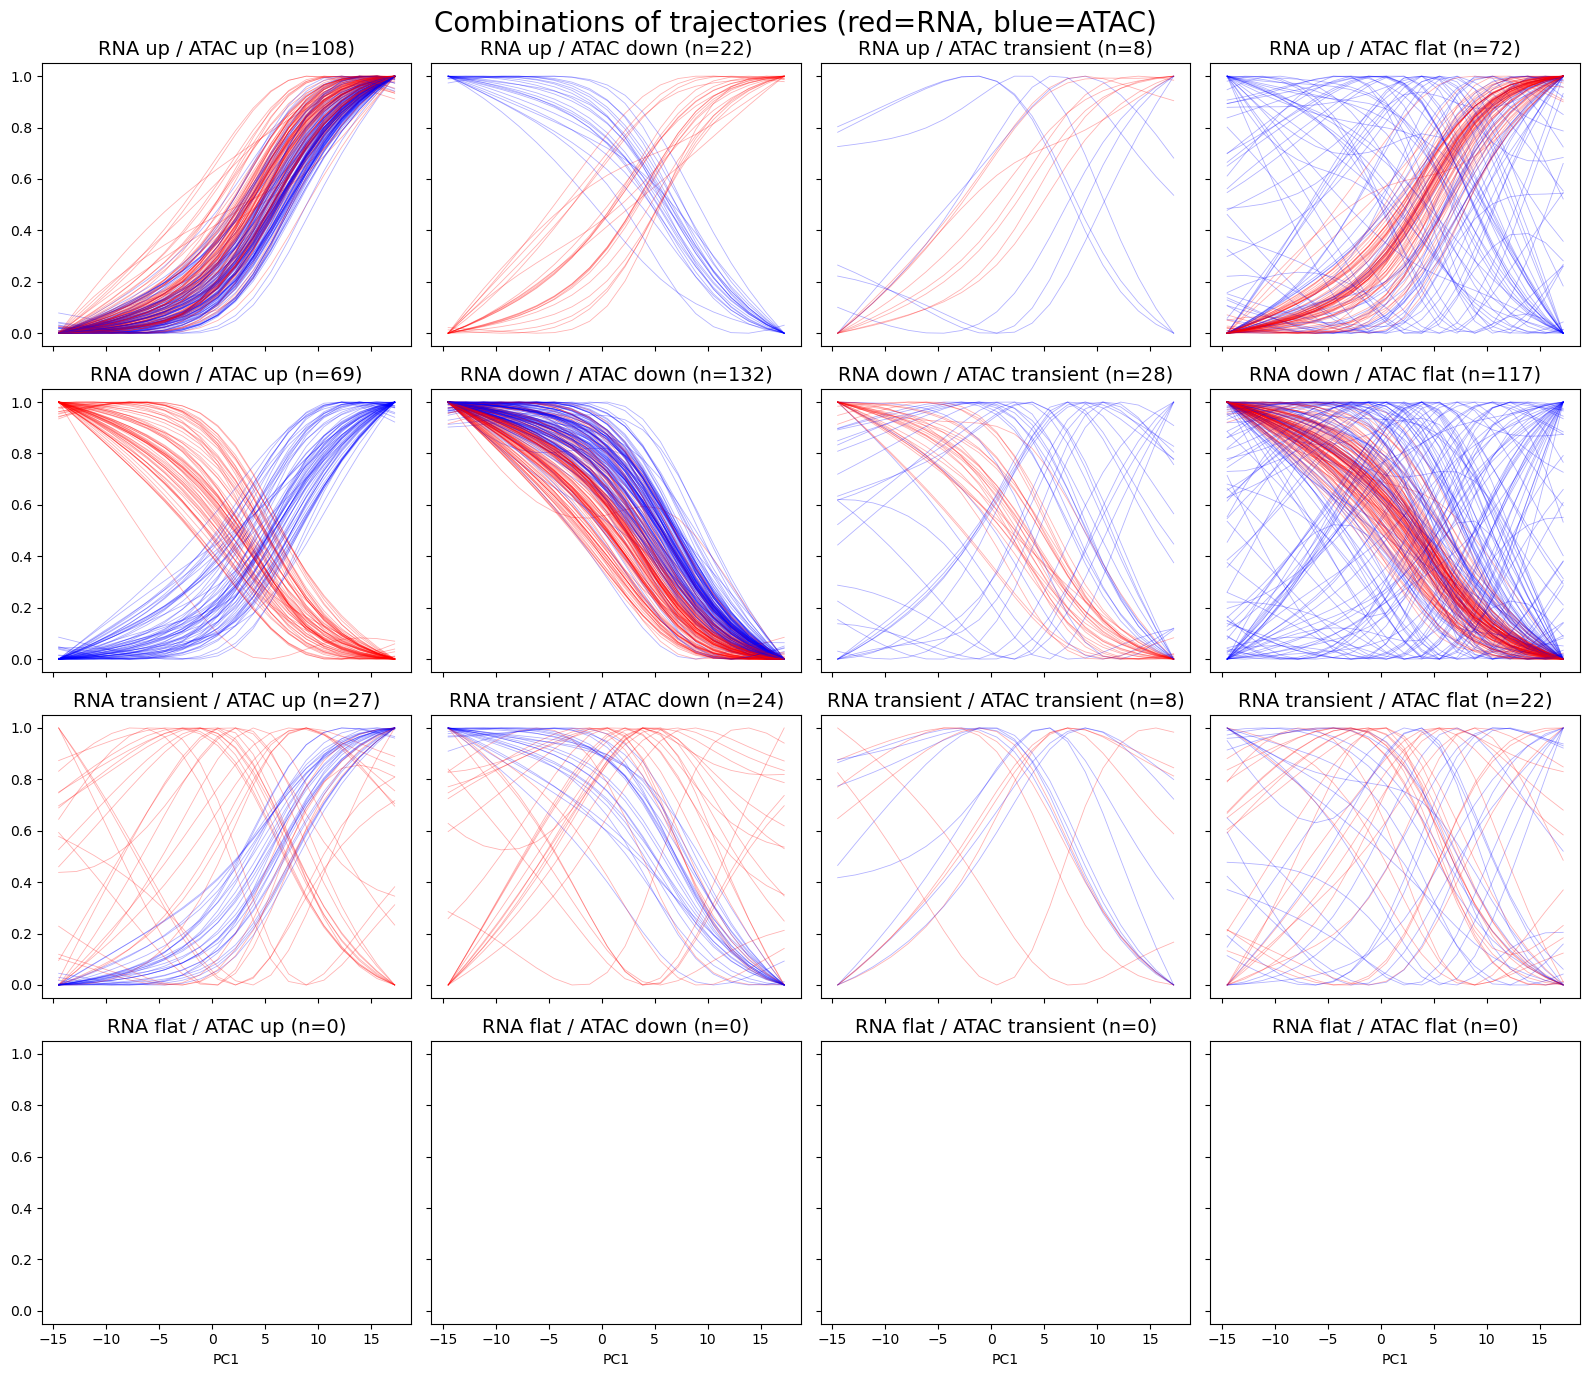

In [14]:
all_genes = {**monotonic_genes, **non_monotonic_genes}
shape_order = ["up", "down", "transient", "flat"]

fig, axs = plt.subplots(4, 4, figsize=(16, 14), sharex=True, sharey=True)

for i, rs in enumerate(shape_order):          # rows: RNA shape
    for j, a_s in enumerate(shape_order):     # columns: ATAC shape
        ax = axs[i, j]
        genes = [g for g, d in all_genes.items() if d["rna_shape"] == rs and d["atac_shape"] == a_s]
        for g in genes:
            ax.plot(grid, all_genes[g]["smooth_rna"],  color="red",  lw=0.6, alpha=0.3)
            ax.plot(grid, all_genes[g]["smooth_atac"], color="blue", lw=0.6, alpha=0.3)
        ax.set_title(f"RNA {rs} / ATAC {a_s} (n={len(genes)})", fontsize=14)

for ax in axs[-1]: ax.set_xlabel("PC1")
plt.suptitle("Combinations of trajectories (red=RNA, blue=ATAC)", fontsize=20)
plt.tight_layout()
plt.savefig(rf"{python_plot_dir}\chromatin_potential\trajectory_combinations.png")
plt.savefig(rf"{python_plot_dir}\chromatin_potential\trajectory_combinations.svg")
plt.show()

Crucially, some of the curves look as through it would be best to remove the 0-count cells. However (!), here the importance of the ratio of count vs. 0-count cells becomes apparent, shaping the curve.

## Trying to identify clusters within the trajectories
First approach is to use only a few discriminant features, secondly we can try using the entire concatenated curves. First we define all the functions we will then apply to the monotonic, non-monotonic and all genes

In [21]:
def half_max_pos(y, grid):  # Finds the midpoint in the grid between the minimum and maximum
    y = (y - y.min()) / (y.max() - y.min())
    return grid[np.argmin(np.abs(y - 0.5))]

def curve_features(gene_dict, gridsize=25):

    t = (grid - grid.min()) / (grid.max() - grid.min())   # normalize time to 0-1
    rows = []

    for g, d in gene_dict.items():
        r, a = np.asarray(d["smooth_rna"]), np.asarray(d["smooth_atac"])

        rows.append(dict(gene=g,
                        monotonicity_r=monotonicity(r)["reversal"],
                        monotonicity_a=monotonicity(a)["reversal"],
                        rna_dir=np.sign(r[-1] - r[0]), 
                        atac_dir=np.sign(a[-1] - a[0]),
                        t_rna=half_max_pos(r, t), 
                        t_atac=half_max_pos(a, t),
                        # RNA
                        rna_max=np.max(r),
                        rna_max_idx=np.argmax(r)/gridsize,
                        rna_min=np.min(r),
                        rna_min_idx=np.argmin(r)/gridsize,
                        # ATAC
                        atac_max=np.max(a),
                        atac_max_idx=np.argmax(a)/gridsize,
                        atac_min=np.min(a),
                        atac_min_idx=np.argmin(a)/gridsize,
                        ))
        
    feat = pd.DataFrame(rows).set_index("gene")
    feat["lag"] = feat.t_atac - feat.t_rna
    feat["lag_dir"] = np.sign(feat["lag"]).astype(int)
    return feat

def get_curves(gene_dict, gridsize=25):
    curves = pd.DataFrame(
        {g: np.concatenate([d["smooth_rna"], d["smooth_atac"]]) for g, d in gene_dict.items()},
        index=[f"rna_{i}" for i in range(gridsize)] + [f"atac_{i}" for i in range(gridsize)],
    ).T
    return curves

def plot_curve_heatmap(feat_df, curves, sortby=["rna_dir", "atac_dir", "t_rna"], n=25, title="all_genes", save=True):
    n = len(grid)

    def mm(A):  # per-gene min-max, so each row spans 0-1
        return (A - A.min(1, keepdims=True)) / np.maximum(np.ptp(A, axis=1, keepdims=True), 1e-12)

    # order genes: by direction group, then by RNA half-max position
    order = feat_df.sort_values(sortby).index
    X = curves.loc[order].values
    R, A = mm(X[:, :n]), mm(X[:, n:])
    extent = [grid.min(), grid.max(), len(order), 0]

    fig, axs = plt.subplots(1, 3, figsize=(6, 4), sharey=True)
    axs[0].imshow(R, aspect="auto", cmap="GnBu", extent=extent); axs[0].set_title("Smoothed RNA")
    axs[1].imshow(A, aspect="auto", cmap="GnBu", extent=extent); axs[1].set_title("Smoothed ATAC")
    im = axs[2].imshow(A - R, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, extent=extent)
    axs[2].set_title("Lag = ATAC - RNA")
    
    plt.colorbar(im, ax=axs[2], shrink=0.4)
    
    for ax in axs: 
        ax.set_xlabel("PC1 = Pseudotime")
    
    axs[0].set_ylabel("genes")
    fig.suptitle("")
    plt.tight_layout()
    if save:
        plt.savefig(rf"{python_plot_dir}\chromatin_potential\curve_heatmap_{title}.png")
        plt.savefig(rf"{python_plot_dir}\chromatin_potential\curve_heatmap_{title}.svg")
    plt.show()
    return

def plot_curve_clusters(feat_df):
    cols = ["t_rna", "t_atac", "lag", "rna_max", "atac_max", "rna_max_idx", "atac_max_idx", "rna_min", "atac_min",
            "rna_min_idx", "atac_min_idx"]

    Z = StandardScaler().fit_transform(feat_df[cols])
    feat_df["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

    emb = umap.UMAP(n_neighbors=20, min_dist=0.1, random_state=0).fit_transform(Z)

    plt.scatter(emb[:, 0], emb[:, 1], c=feat_df["cluster"], cmap="viridis", s=10)
    plt.xlabel("UMAP1"); plt.ylabel("UMAP2")
    plt.show()
    return

def plot_curve_violinplots(feat_df, cols_plot=["rna_max_idx", "atac_max_idx"]):
    
    d = feat_df[feat_df["cluster"].isin([0, 1, 2])]

    ncol = 3
    nrow = int(np.ceil(len(cols_plot) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))

    for ax, c in zip(axs.ravel(), cols_plot):
        sns.violinplot(data=d, x="cluster", y=c, inner=None, cut=0, color="lightgray",
                    linewidth=0.8, density_norm="width", ax=ax)
        sns.stripplot(data=d, x="cluster", y=c, size=2, alpha=0.5, jitter=0.25,
                    color="black", ax=ax)
        ax.set_title(c)

    for ax in axs.ravel()[len(cols_plot):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    return

## Monotonic Genes

In [16]:
mono_feat = curve_features(monotonic_genes, gridsize)
mono_curves = get_curves(monotonic_genes, gridsize)

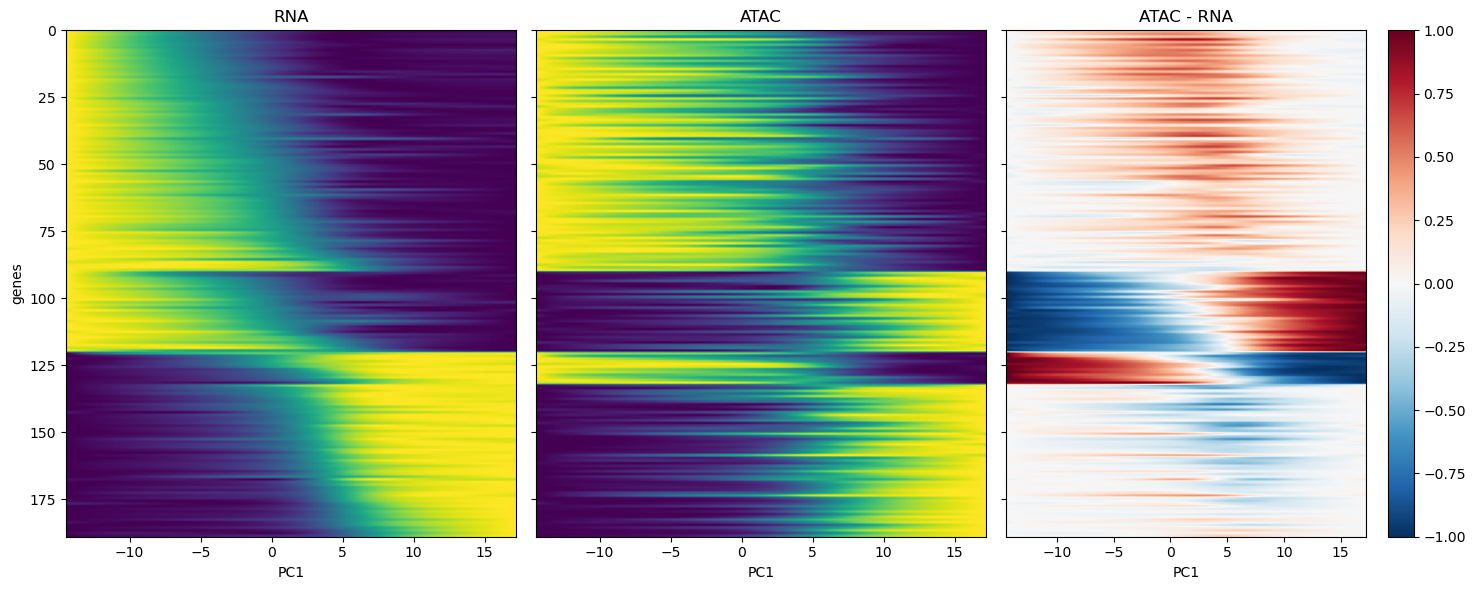

  File "c:\Users\Nikla\anaconda3\envs\dynavelo\lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "c:\Users\Nikla\anaconda3\envs\dynavelo\lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
  File "c:\Users\Nikla\anaconda3\envs\dynavelo\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\Nikla\anaconda3\envs\dynavelo\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Nikla\anaconda3\envs\dynavelo\lib\subprocess.py", line 1456, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


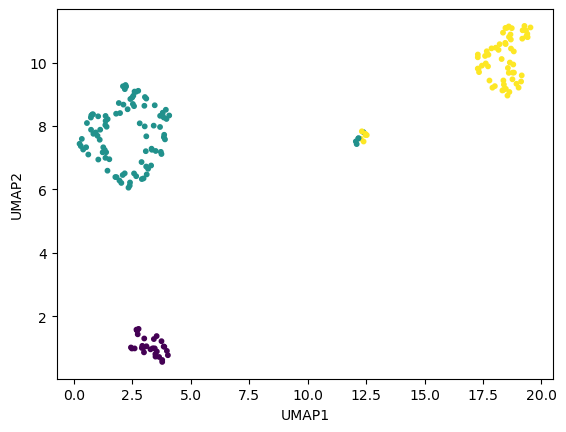

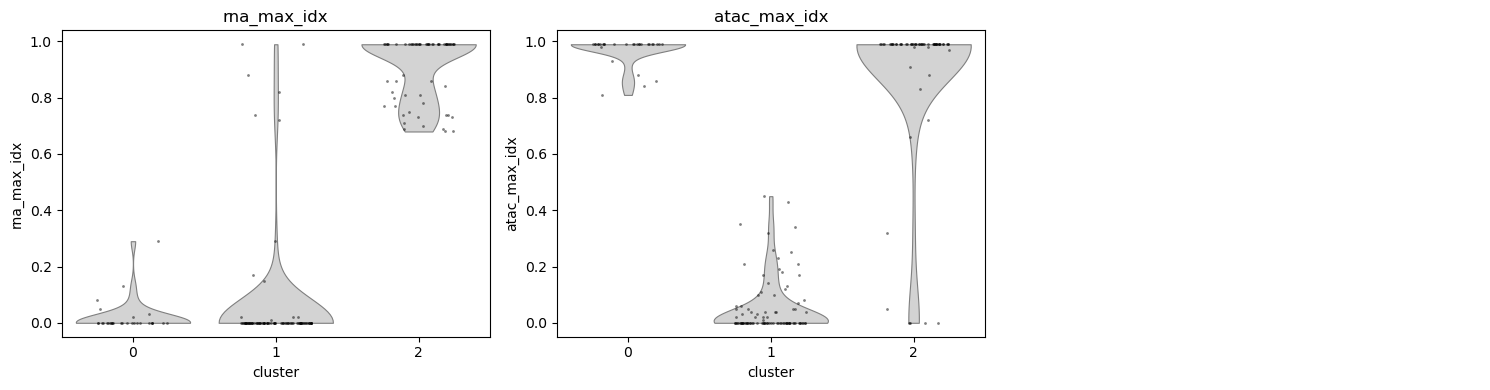

In [40]:
plot_curve_heatmap(mono_feat, mono_curves, n=gridsize)
plot_curve_clusters(mono_feat)
plot_curve_violinplots(mono_feat)

## Non-Monotonic Genes

In [17]:
non_mono_feat = curve_features(non_monotonic_genes, gridsize)
non_mono_curves = get_curves(non_monotonic_genes, gridsize)

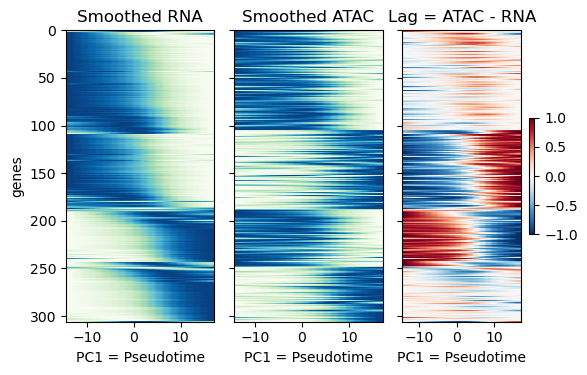

In [22]:
plot_curve_heatmap(non_mono_feat, non_mono_curves, n=gridsize, save=False)
# plot_curve_clusters(non_mono_feat)
# plot_curve_violinplots(non_mono_feat)

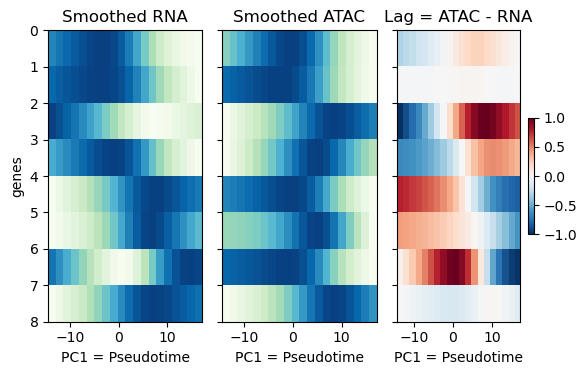

In [28]:
trans_subset = shapes.loc[(shapes["rna_shape"] == "transient") & (shapes["atac_shape"] == "transient"),:].index.tolist()
trans_feat = non_mono_feat.loc[trans_subset,:]
trans_genes = {v: non_monotonic_genes[v] for v in trans_subset}
trans_curves = get_curves(trans_genes, gridsize)
plot_curve_heatmap(trans_feat, trans_curves, n=gridsize, save=False)

## All genes

In [19]:
all_genes = monotonic_genes | non_monotonic_genes

all_feat = curve_features(all_genes, gridsize)
all_curves = get_curves(all_genes, gridsize)

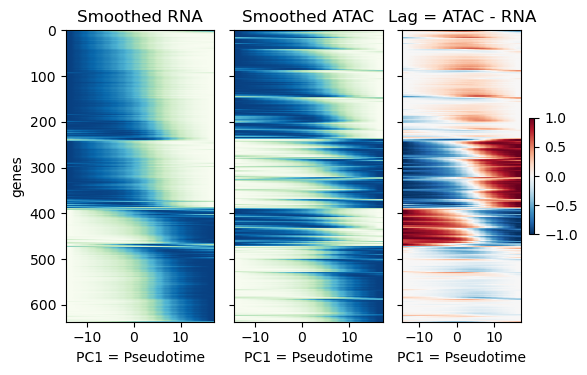

In [20]:
plot_curve_heatmap(all_feat, all_curves, sortby=["rna_dir", "atac_dir", "t_rna", "t_atac"], n=gridsize)
# plot_curve_clusters(all_feat)
# plot_curve_violinplots(all_feat)
# "rna_dir", "atac_dir", "t_rna"

## Analysis of pseudotime lag
We first carry this out for the monotonic genes. However, this is not strictly required for the assumptions we are trying to check of chromatin velocity, where the RNA signal lags behind the ATAC signal.

In [43]:
same_dir_mono_feats = mono_feat[(mono_feat["rna_dir"] == mono_feat["atac_dir"])]
lag_sorted_feats = same_dir_mono_feats.sort_values(["lag"], ascending=False)
pca_data = adata_rna.obsm["X_pca"][:,:2]

Importantly the lag direction is as follows:
- Negative lag: ATAC reaches half max at an earlier point along PC1 (signal we want)
- Positive lag: RNA reaches half max at an earlier point along PC1 

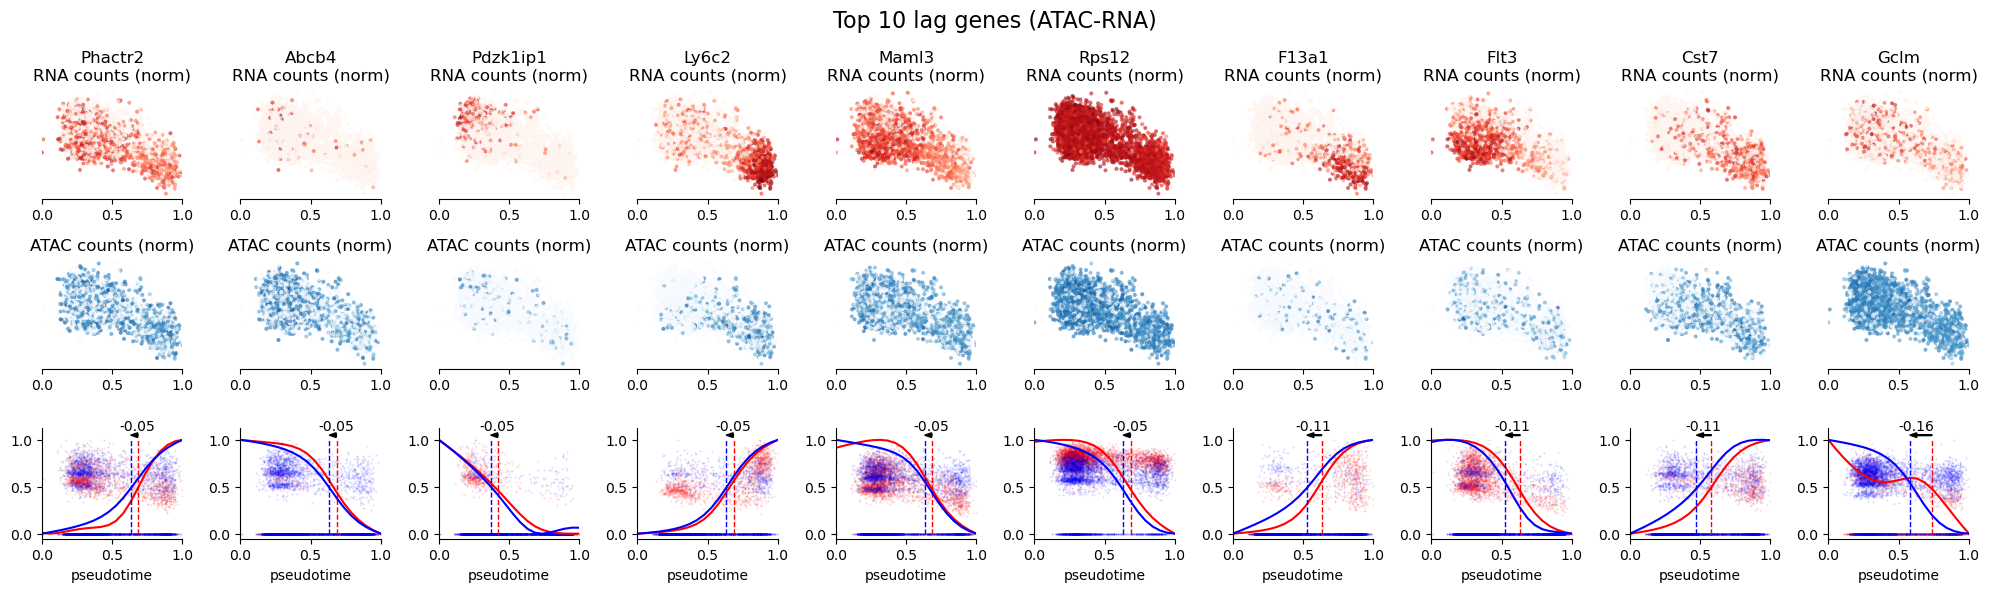

In [44]:
num_genes = 10

min_x = np.min(pca_data[:, 0])
max_x = np.max(pca_data[:, 0])
x_norm = (pca_data[:, 0] - min_x) / (max_x - min_x)

grid_norm = np.linspace(0, 1, gridsize)

fig, axs = plt.subplots(nrows=3, ncols=num_genes, figsize=(num_genes*2, 6))

for i, gene in enumerate(lag_sorted_feats.index.tolist()[-num_genes:]):

    axs[0, i].scatter(x_norm, pca_data[:, 1], c=adata_rna[:, gene].X.toarray(), cmap="Reds", s=4, alpha=0.5)
    axs[0, i].set_title(f"{gene}\nRNA counts (norm)", fontsize=12)

    axs[1, i].scatter(x_norm, pca_data[:, 1], c=adata_atac[:, gene].X.toarray(), cmap="Blues", s=4, alpha=0.5)
    axs[1, i].set_title("ATAC counts (norm)", fontsize=12)

    for r in (0, 1):
        axs[r, i].spines[['left', 'top', 'right']].set_visible(False)
        axs[r, i].get_yaxis().set_visible(False)

    curve_data = mono_curves.loc[gene, :].values

    t_rna = mono_feat.loc[gene, "t_rna"] #(mono_feat.loc[gene, "t_rna"] * max_x - min_x) / (max_x - min_x)
    t_atac = mono_feat.loc[gene, "t_atac"] #(mono_feat.loc[gene, "t_atac"] * max_x - min_x) / (max_x - min_x)

    gene_scatter_data_rna = MinMaxScaler().fit_transform(
        adata_rna[:, gene].X.toarray()
    )

    gene_scatter_data_atac = MinMaxScaler().fit_transform(
        adata_atac[:, gene].X.toarray()
    )
    axs[2, i].scatter(x_norm, gene_scatter_data_rna, c="red", s=2, alpha=0.15, linewidths=0)
    axs[2, i].scatter(x_norm, gene_scatter_data_atac, c="blue", s=2, alpha=0.15, linewidths=0)
    
    axs[2, i].plot(grid_norm, curve_data[:gridsize], c="red")
    axs[2, i].plot(grid_norm, curve_data[gridsize:], c="blue")
    axs[2, i].vlines(t_rna, ymin=0, ymax=1, color="red", zorder=1, linestyle="dashed", linewidth=1)
    axs[2, i].vlines(t_atac, ymin=0, ymax=1, color="blue", zorder=2, linestyle="dashed", linewidth=1)
    axs[2, i].arrow(t_rna, 1.05, t_atac - t_rna, 0, zorder=0, width=0.01,
                    head_width=0.05, head_length=0.05,  
                    facecolor="black", length_includes_head=True)
    axs[2, i].text(t_atac-0.08, 1.10, f"{np.round(t_atac - t_rna,2)}", fontsize=10)

    axs[2, i].spines[['top', 'right']].set_visible(False)

    for r in range(3):
        axs[r, i].set_xlim(0, 1)
    axs[2, i].set_xlabel("pseudotime")

fig.suptitle("Top 10 lag genes (ATAC-RNA)", fontsize=16)
plt.tight_layout()
plt.savefig(rf"{python_plot_dir}\chromatin_potential\lag_genes_neg.png")
plt.savefig(rf"{python_plot_dir}\chromatin_potential\lag_genes_neg.svg")
plt.show()

Identify curves where there is a sharp change in ATAC signal before the RNA signal, independent of the global halfway point.

In [45]:
def first_step_half_pos(y, grid, thr=0.2):
    """
    Position of the half-height of the first significant rise.

    thr    : slope threshold as a fraction of the max slope. Below it, the curve
             counts as flat (saddle/plateau).
    smooth : optional Gaussian sigma (in grid points) to suppress noise.
    """
    y = np.asarray(y, float)
    grid = np.asarray(grid, float)

    y = (y - y.min()) / (y.max() - y.min())

    dy = np.gradient(y, grid)
    steep = np.abs(dy) > thr * np.abs(dy).max()
    if not steep.any():
        return 0

    i0 = np.argmax(steep)
    if i0 < 5:  # This would just be noise
        return 0                                # first steep point
    below = ~steep[i0:]                        # where does the slope fall off again?
    i1 = i0 + (np.argmax(below) if below.any() else len(below) - 1)

    base = y[: i1 + 1].min()                   # level before the step
    top = y[i1]                                # level at the saddle/plateau
    half = base + 0.5 * (top - base)

    # first crossing of `half`, linearly interpolated
    j = np.argmax(y[: i1 + 1] >= half)
    if j == 0:
        return grid[0]
    frac = (half - y[j - 1]) / (y[j] - y[j - 1])
    return grid[j - 1] + frac * (grid[j] - grid[j - 1])

In [46]:
mono_same_dir_genes = mono_feat[mono_feat["rna_dir"]==mono_feat["atac_dir"]].index.tolist()

mono_feat["t_first_atac"] = mono_feat["t_atac"]
mono_feat["t_first_rna"] = mono_feat["t_rna"]

t = (grid - grid.min()) / (grid.max() - grid.min())   # normalize time to 0-1
rows = []

for gene in mono_same_dir_genes:
    r, a = np.asarray(monotonic_genes[gene]["smooth_rna"]), np.asarray(monotonic_genes[gene]["smooth_atac"])

    t_first_rna = first_step_half_pos(r, t, thr=0.2), 
    t_first_atac = first_step_half_pos(a, t, thr=0.2),

    mono_feat.loc[gene, "t_first_atac"] = t_first_atac
    mono_feat.loc[gene, "t_first_rna"] = t_first_rna


In [47]:
atac_first_signal = mono_feat[(mono_feat["t_first_atac"] < mono_feat["t_rna"]) 
                              & (mono_feat["t_first_atac"] != 0)
                              & (mono_feat["t_first_atac"] < mono_feat["t_first_rna"])
                              ]
atac_first_signal_samedir = atac_first_signal[(atac_first_signal["rna_dir"] == atac_first_signal["atac_dir"])]
#atac_first_signal_samedir.to_csv(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_gene_subset_atacfirst.csv", index=True)

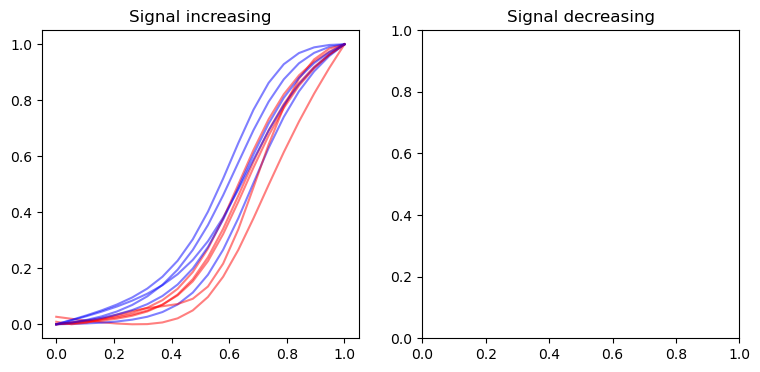

In [48]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9,4))

for gene in atac_first_signal_samedir.index.tolist():
    r, a = np.asarray(monotonic_genes[gene]["smooth_rna"]), np.asarray(monotonic_genes[gene]["smooth_atac"])

    if mono_feat.loc[gene, "rna_dir"] == 1:
        axs[0].plot(t, r, c="red", alpha=0.5)
        axs[0].plot(t, a, c="blue", alpha=0.5)
    else:
        axs[1].plot(t, r, c="red", alpha=0.5)
        axs[1].plot(t, a, c="blue", alpha=0.5)
    axs[0].set_title("Signal increasing")
    axs[1].set_title("Signal decreasing")
plt.show()

## Chromatin Velocity
Clearly some of the genes follow the expected behavior that is assumed by chromatin velocity. We subset to this set of genes and then compute our velocities.

In [29]:
# Load z-score data and compute correlations with aggregated peak data
z_scores = sc.read_h5ad(rf"{python_data_dir}\z_scores_raw.h5ad")
z_scores.obs_names = [i[9:-2] for i in z_scores.obs_names.values]
z_scores = z_scores[z_scores.obs_names.isin(rna_df.index.values),:]
z_scores = pd.DataFrame(z_scores.X, index=z_scores.obs_names.values, columns=z_scores.var_names.values)

z_scores = minmax_cols(z_scores)
mono_atac_curves = mono_curves.iloc[mono_curves.index.isin(list(monotonic_genes.keys())), gridsize:]
z_score_curves = pd.DataFrame(np.zeros(shape=(len(z_scores.T), gridsize)), index=z_scores.columns, columns=[f"z_{i}" for i in range(gridsize)])
assert (rna_df.index.values == z_scores.index.values).all()

In [30]:
skipped_zero = []

for gene in z_score_curves.index.values: 
    
    if (z_scores.loc[:,gene] == 0).all():
        skipped_zero.append(gene)
        continue
    
    z_score_curves.loc[gene,:] = np.asarray(gaussian_smooth_on_grid(X_pca[:, 0], z_scores.loc[:,gene], grid))

In [31]:
z_score_curves.to_csv(rf"{python_data_dir}\pmtr_peak_sub\z_score_curves.csv", index=True, header=True)
mono_atac_curves.to_csv(rf"{python_data_dir}\pmtr_peak_sub\mono_atac_curves.csv", index=True, header=True)

In [32]:
A = mono_atac_curves.values   # (n_atac_genes, n_points)
Z = z_score_curves.values     # (n_z_genes, n_points)

# Standardize each row (mean 0, std 1)
A_std = (A - A.mean(axis=1, keepdims=True)) / A.std(axis=1, keepdims=True)
Z_std = (Z - Z.mean(axis=1, keepdims=True)) / Z.std(axis=1, keepdims=True)

# Pearson r for every (atac gene, z gene) pair
corrs = pd.DataFrame(
    A_std @ Z_std.T / A.shape[1],
    index=mono_atac_curves.index,
    columns=z_score_curves.index,
)

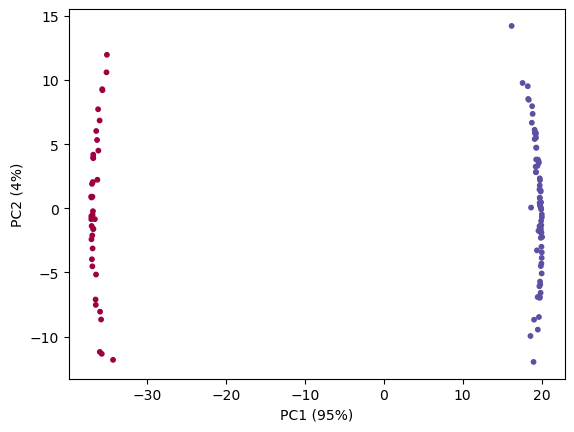

<Axes: >

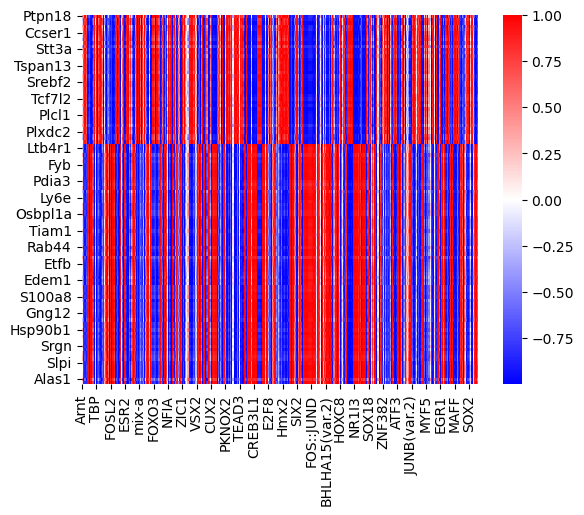

In [33]:
Z = StandardScaler().fit_transform(corrs)
clusters = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(Z)

P = PCA(n_components=2).fit(Z)
emb = P.transform(Z)

plt.scatter(emb[:, 0], emb[:, 1], c=clusters, cmap="Spectral", s=10)
plt.xlabel(f"PC1 ({P.explained_variance_ratio_[0]:.0%})")
plt.ylabel(f"PC2 ({P.explained_variance_ratio_[1]:.0%})")
plt.show()

corrs["clusters"] = clusters
order = corrs["clusters"].sort_values().index
corrs_sorted=corrs.loc[order]

sns.heatmap(corrs_sorted, cmap="bwr")

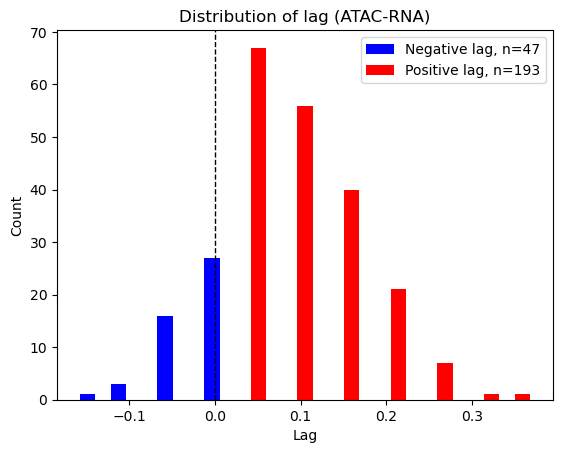

In [49]:
lag = lag_sorted_feats["lag"]
bins = np.linspace(lag.min(), lag.max(), 30)

plt.hist(lag[lag <= 0], bins=bins, color="blue", label=f"Negative lag, n={len(lag[lag <= 0])}")
plt.hist(lag[lag > 0], bins=bins, color="red", label=f"Positive lag, n={len(lag[lag > 0])}")

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Distribution of lag (ATAC-RNA)")
plt.xlabel("Lag")
plt.ylabel("Count")
plt.legend()

plt.savefig(rf"{python_plot_dir}\chromatin_potential\lag_distribution.png")
plt.savefig(rf"{python_plot_dir}\chromatin_potential\lag_distribution.svg")

plt.show()

In [50]:
lag_subset_feats = lag_sorted_feats[(lag_sorted_feats["rna_dir"] == lag_sorted_feats["atac_dir"]) & (lag_sorted_feats["lag"] < 0)]
lag_subset_feats.to_csv(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_gene_subset.csv", index=True)
all_feat.to_csv(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_all_genes.csv", index=True)

## Testing branching

In [20]:
ad_t = adata_rna_all_lin.copy()
assert adata_atac_all_lin.obs_names.equals(ad_t.obs_names)
assert adata_atac_all_lin.var_names.equals(ad_t.var_names)

sc.pp.pca(adata_atac_all_lin, n_comps=30)
rna_pc = ad_t.obsm["X_pca"][:, :30]
atac_pc = adata_atac_all_lin.obsm["X_pca"][:, :30]
ad_t.obsm["X_joint"] = np.hstack([
    rna_pc / rna_pc.std(), atac_pc / atac_pc.std()
])

sc.pp.neighbors(ad_t, n_neighbors=30, use_rep="X_joint")
sc.tl.diffmap(ad_t)

dm = ad_t.obsm["X_diffmap"]
root = (ad_t.obs["predicted.id"] == "LT").to_numpy()
ad_t.uns["iroot"] = np.argmin(
    np.linalg.norm(dm - dm[root].mean(axis=0), axis=1)
)
sc.tl.dpt(ad_t, n_branchings=1)

C_rna = adata_rna_all_lin.layers["counts"]
C_atac = adata_atac_all_lin.layers["counts"]
C_rna = C_rna.toarray() if sp.issparse(C_rna) else np.asarray(C_rna)
C_atac = C_atac.toarray() if sp.issparse(C_atac) else np.asarray(C_atac)

pt = ad_t.obs["dpt_pseudotime"].to_numpy()
groups = ad_t.obs["dpt_groups"].astype(str).to_numpy()
depth_rna = adata_rna_all_lin.obs["depth"].to_numpy()
depth_atac = adata_atac_all_lin.obs["depth"].to_numpy()

branch_subsets = {}

for k in ["1", "2"]:
    idx = np.flatnonzero(np.isin(groups, ["0", k]))
    x = pt[idx]
    grid = np.linspace(x.min(), x.max(), gridsize)
    sigma = 0.1 * (grid.max() - grid.min())

    R = kernel_rate(x, C_rna[idx], depth_rna[idx], grid, sigma)
    A = kernel_rate(x, C_atac[idx], depth_atac[idx], grid, sigma)

    mono = {}
    for i, g in enumerate(adata_rna_all_lin.var_names):
        if C_rna[idx, i].sum() == 0 or C_atac[idx, i].sum() == 0:
            continue

        r, a = R[:, i], A[:, i]
        if r.max() <= 0 or a.max() <= 0:
            continue

        r, a = minmax01(r / r.max()), minmax01(a / a.max())
        sr, _ = classify_shape(r, TOL, MIN_RANGE)
        sa, _ = classify_shape(a, TOL, MIN_RANGE)

        if sr in ("up", "down") and sa in ("up", "down"):
            mono[g] = {"smooth_rna": r, "smooth_atac": a}

    feat = curve_features(mono, gridsize)
    branch_subsets[k] = feat[
        (feat["lag"] < 0) & (feat["rna_dir"] == feat["atac_dir"])
    ]
    print(f"Branch {k}: {len(mono)} monotonic genes, "
          f"{len(branch_subsets[k])} ATAC-leading genes")

s1, s2 = (set(v.index) for v in branch_subsets.values())
print(f"Branch 1: {len(s1)}, Branch 2: {len(s2)}, Shared: {len(s1 & s2)}")

velo_genes = sorted(s1 | s2)  # use s1 & s2 to require both branches
np.array(velo_genes)

Branch 1: 146 monotonic genes, 15 ATAC-leading genes
Branch 2: 167 monotonic genes, 42 ATAC-leading genes
Branch 1: 15, Branch 2: 42, Shared: 2


array(['Adgrl2', 'Alox5ap', 'Anxa3', 'Baz1a', 'Cst7', 'Ctsg', 'Elane',
       'Ermap', 'Etfb', 'Fcgr2b', 'Gclm', 'Gfi1b', 'Gpc1', 'Gpr171',
       'Gsr', 'Gstm5', 'H3f3a', 'H3f3b', 'Hp', 'Ifngr1', 'Ifrd2', 'Kel',
       'Klf1', 'Lman2', 'Lncpint', 'Ltb4r1', 'Ly6c2', 'Magi2', 'Mmrn1',
       'Mpo', 'Ms4a3', 'Msrb1', 'Mt1', 'Nkg7', 'Plac8', 'Prkcsh',
       'Prss57', 'Prtn3', 'Ptpn18', 'Rab4a', 'Rassf2', 'Rpl21', 'Rps13',
       'Rps24', 'S100a8', 'Sdf2l1', 'Srgn', 'Ssr2', 'Supt3', 'Tanc2',
       'Tfdp1', 'Tmsb4x', 'Tpk1', 'Tut7', 'Wwox'], dtype='<U7')